# Fakeddit Multimodal Misinformation Detection
### Stage 3 — Fusion Model & Modality Comparison

**Goal of this notebook:** combine text (RoBERTa) and image (CLIP) into a single fused model, and put text-only, image-only, and fusion on **one shared, aligned test set** so the Stage 1 vs. Stage 2 comparison (which used two different splits) finally becomes rigorous.

**This notebook covers:**
1. Re-extract RoBERTa text embeddings on the `splits_multimodal` IDs (Stage 1's RoBERTa embeddings were computed on a different, pre-filter split, so they don't line up with Stage 2's image-confirmed IDs)
2. Load Stage 2's CLIP image embeddings for the same IDs
3. Build the 1280-d fused representation (768-d text + 512-d image, concatenated)
4. Train a small MLP fusion head
5. Evaluate all three models — text-only, image-only, fusion — **on the exact same test set**, with Accuracy, Macro-F1, AUROC, and ECE
6. Modality-dominance analysis: on rows where text and image predictions *disagree*, which one does the fusion model side with more often?
7. Save everything with the same idempotent, resumable conventions


## Step 0 — Setup

In [ ]:
!pip install -q transformers sentencepiece scikit-learn matplotlib pandas tqdm joblib


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DRIVE_ROOT = '/content/drive/MyDrive/fakeddit_calibration'
LABEL_COL = '3_way_label'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
print(f"Drive root: {DRIVE_ROOT}")


Mounted at /content/drive
Using device: cuda
Drive root: /content/drive/MyDrive/fakeddit_calibration


## Step 1 — Load the shared split and CLIP embeddings

This is the key fix from Stages 1–2: everything in this notebook uses `splits_multimodal/` (the filtered, image-confirmed split from Stage 2) as the **single shared split**. Stage 1's text-only numbers were computed on a different split and are only a directional reference from here on, not directly comparable row-for-row until re-evaluated here.


In [ ]:
splits_dir = f'{DRIVE_ROOT}/metadata/splits_multimodal'
train_df = pd.read_csv(f'{splits_dir}/train.csv')
val_df   = pd.read_csv(f'{splits_dir}/val.csv')
test_df  = pd.read_csv(f'{splits_dir}/test.csv')
print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")

# Stage 2's CLIP embeddings, keyed by post id
clip_cache = np.load(f'{DRIVE_ROOT}/embeddings/clip_image_embeddings.npz', allow_pickle=True)
id_to_clip = dict(zip(clip_cache['ids'].tolist(), clip_cache['embeddings']))
print(f"CLIP embeddings available for {len(id_to_clip)} posts")


Train: 13934  Val: 2986  Test: 2986
CLIP embeddings available for 19906 posts


## Step 2 — Re-extract RoBERTa text embeddings on the shared split

Stage 1's cached RoBERTa embeddings were computed for a different (pre-filter) train/val/test split, so they can't be reused directly here, the row order and the set of IDs don't match. This re-extracts them, but only for the ~19,906 posts in `splits_multimodal` (not all 30,000), so it's a smaller, faster pass than Stage 1's original run. Cached separately from Stage 1's file so neither overwrites the other.


In [ ]:
from transformers import RobertaTokenizer, RobertaModel

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
roberta = RobertaModel.from_pretrained('roberta-base').to(device).eval()

@torch.no_grad()
def extract_roberta_embeddings(texts, batch_size=32):
    embeddings = []
    for i in tqdm(range(0, len(texts), batch_size), desc='Extracting RoBERTa embeddings'):
        batch = texts[i:i + batch_size]
        enc = tokenizer(list(batch), padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
        out = roberta(**enc)
        cls_emb = out.last_hidden_state[:, 0, :].cpu().numpy()
        embeddings.append(cls_emb)
    return np.concatenate(embeddings, axis=0)

def get_or_create_text_embeddings(split_df, split_name):
    path = f'{DRIVE_ROOT}/embeddings/roberta_multimodal_{split_name}.npy'
    if os.path.exists(path):
        print(f"Loading cached {split_name} text embeddings (multimodal split).")
        emb = np.load(path)
    else:
        emb = extract_roberta_embeddings(split_df['clean_title'].tolist())
        np.save(path, emb)
        print(f"Saved {split_name} text embeddings: {emb.shape} -> {path}")
    return dict(zip(split_df['id'], emb))

id_to_text_train = get_or_create_text_embeddings(train_df, 'train')
id_to_text_val   = get_or_create_text_embeddings(val_df, 'val')
id_to_text_test  = get_or_create_text_embeddings(test_df, 'test')

id_to_text = {**id_to_text_train, **id_to_text_val, **id_to_text_test}
print(f"\nTotal text embeddings available: {len(id_to_text)}")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

...

Saved train text embeddings: (13934, 768) -> /content/drive/MyDrive/fakeddit_calibration/embeddings/roberta_multimodal_train.npy


Extracting RoBERTa embeddings:   0%|          | 0/94 [00:00<?, ?it/s]

Saved val text embeddings: (2986, 768) -> /content/drive/MyDrive/fakeddit_calibration/embeddings/roberta_multimodal_val.npy


Extracting RoBERTa embeddings:   0%|          | 0/94 [00:00<?, ?it/s]

Saved test text embeddings: (2986, 768) -> /content/drive/MyDrive/fakeddit_calibration/embeddings/roberta_multimodal_test.npy

Total text embeddings available: 19906


## Step 3 — Assemble text-only, image-only, and fused arrays (all on the same IDs)




In [ ]:
def build_arrays(split_df):
    ids = split_df['id'].tolist()
    X_text = np.stack([id_to_text[i] for i in ids])
    X_image = np.stack([id_to_clip[i] for i in ids])
    X_fusion = np.concatenate([X_text, X_image], axis=1)
    y = split_df[LABEL_COL].values
    return X_text, X_image, X_fusion, y

X_text_train, X_image_train, X_fusion_train, y_train = build_arrays(train_df)
X_text_val,   X_image_val,   X_fusion_val,   y_val   = build_arrays(val_df)
X_text_test,  X_image_test,  X_fusion_test,  y_test  = build_arrays(test_df)

print(f"Text:   {X_text_train.shape}")
print(f"Image:  {X_image_train.shape}")
print(f"Fusion: {X_fusion_train.shape}  (768 text + 512 image = 1280)")


Text:   (13934, 768)
Image:  (13934, 512)
Fusion: (13934, 1280)  (768 text + 512 image = 1280)


## Step 4 — ECE helper (same implementation as Stages 1–2)

In [ ]:
def compute_ece(y_true, y_proba, n_bins=10):
    confidences = np.max(y_proba, axis=1)
    predictions = np.argmax(y_proba, axis=1)
    accuracies = (predictions == y_true).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences > lo) & (confidences <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append({'bin_range': [float(round(lo, 2)), float(round(hi, 2))],
                               'accuracy': float(acc_in_bin), 'confidence': float(conf_in_bin),
                               'proportion': float(prop_in_bin)})
    return float(ece), bin_stats


## Step 5 — Train and evaluate all three models on the shared split (idempotent)

Text-only and image-only are retrained here, so every number in the final comparison table comes from the exact same test set. The fusion model uses a small MLP (`hidden_layer_sizes=(256,)`) rather than logistic regression, since it needs to learn how to combine two different embedding spaces, not just draw a linear boundary in one.

Same idempotency pattern as before


In [ ]:
SUMMARY_PATH = f'{DRIVE_ROOT}/metadata/fusion_stage_summary.json'
MODELS_DIR = f'{DRIVE_ROOT}/models'
FIGURES_DIR = f'{DRIVE_ROOT}/figures'

def train_and_eval(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    acc = float(accuracy_score(y_test, y_pred))
    macro_f1 = float(f1_score(y_test, y_pred, average='macro'))
    auroc = float(roc_auc_score(y_test, y_proba, multi_class='ovr'))
    ece, bin_stats = compute_ece(y_test, y_proba, n_bins=10)
    conf_matrix = confusion_matrix(y_test, y_pred)
    joblib.dump(model, f'{MODELS_DIR}/{name}_shared_split.joblib')
    return {
        'accuracy': round(acc, 4), 'macro_f1': round(macro_f1, 4),
        'auroc': round(auroc, 4), 'ece': round(ece, 4),
        'calibration_bins': bin_stats, 'confusion_matrix': conf_matrix.tolist(),
    }, y_pred, y_proba

if os.path.exists(SUMMARY_PATH):
    print("Cached fusion-stage results found — loading instead of retraining.\n")
    with open(SUMMARY_PATH) as f:
        results = json.load(f)
    text_pred = np.array(results['_predictions']['text'])
    image_pred = np.array(results['_predictions']['image'])
    fusion_pred = np.array(results['_predictions']['fusion'])
else:
    print("No cached fusion-stage results — training all three models now.\n")
    results = {}

    print("Training text-only (shared split)...")
    results['text_only'], text_pred, text_proba = train_and_eval(
        'text_only', LogisticRegression(max_iter=2000, random_state=SEED),
        X_text_train, y_train, X_text_test, y_test)

    print("Training image-only (shared split)...")
    results['image_only'], image_pred, image_proba = train_and_eval(
        'image_only', LogisticRegression(max_iter=2000, random_state=SEED),
        X_image_train, y_train, X_image_test, y_test)

    print("Training fusion (MLP)...")
    results['fusion'], fusion_pred, fusion_proba = train_and_eval(
        'fusion', MLPClassifier(hidden_layer_sizes=(256,), max_iter=300, random_state=SEED, early_stopping=True),
        X_fusion_train, y_train, X_fusion_test, y_test)

    results['seed'] = SEED
    results['n_test'] = len(y_test)
    results['_predictions'] = {
        'text': text_pred.tolist(), 'image': image_pred.tolist(), 'fusion': fusion_pred.tolist(),
    }
    with open(SUMMARY_PATH, 'w') as f:
        json.dump(results, f, indent=2)
    print(f"\nSaved -> {SUMMARY_PATH}")

comparison = pd.DataFrame({
    'Text-only':  [results['text_only'][k] for k in ['accuracy', 'macro_f1', 'auroc', 'ece']],
    'Image-only': [results['image_only'][k] for k in ['accuracy', 'macro_f1', 'auroc', 'ece']],
    'Fusion':     [results['fusion'][k] for k in ['accuracy', 'macro_f1', 'auroc', 'ece']],
}, index=['Accuracy', 'Macro-F1', 'AUROC', 'ECE'])

print("\n=== All three models, same shared test set ===")
print(comparison.round(4))


No cached fusion-stage results — training all three models now.

Training text-only (shared split)...
Training image-only (shared split)...
Training fusion (MLP)...

Saved -> /content/drive/MyDrive/fakeddit_calibration/metadata/fusion_stage_summary.json

=== All three models, same shared test set ===
          Text-only  Image-only  Fusion
Accuracy     0.7415      0.7656  0.8282
Macro-F1     0.6707      0.7838  0.8419
AUROC        0.8705      0.8928  0.9355
ECE          0.0393      0.0306  0.0525


## Step 6 — Modality-dominance analysis

Important Question to check: When text and image *disagree* with each other, does the fusion model just default to whichever modality is individually stronger, or does it genuinely combine them? This looks at every test example where the text-only and image-only predictions differ, and checks which one the fusion model agreed with more often.


In [ ]:
y_test_arr = np.array(y_test)
disagreement_mask = (text_pred != image_pred)
n_disagree = disagreement_mask.sum()
print(f"Text and image disagree on {n_disagree} / {len(y_test_arr)} test examples ({n_disagree/len(y_test_arr):.1%})")

if n_disagree > 0:
    fusion_agrees_with_text = (fusion_pred[disagreement_mask] == text_pred[disagreement_mask]).mean()
    fusion_agrees_with_image = (fusion_pred[disagreement_mask] == image_pred[disagreement_mask]).mean()
    fusion_correct_on_disagreements = (fusion_pred[disagreement_mask] == y_test_arr[disagreement_mask]).mean()
    text_correct_on_disagreements = (text_pred[disagreement_mask] == y_test_arr[disagreement_mask]).mean()
    image_correct_on_disagreements = (image_pred[disagreement_mask] == y_test_arr[disagreement_mask]).mean()

    print(f"\nOn disagreement cases specifically:")
    print(f"  Fusion sides with text:  {fusion_agrees_with_text:.1%}")
    print(f"  Fusion sides with image: {fusion_agrees_with_image:.1%}")
    print(f"\n  Text-only accuracy on these cases:   {text_correct_on_disagreements:.1%}")
    print(f"  Image-only accuracy on these cases:  {image_correct_on_disagreements:.1%}")
    print(f"  Fusion accuracy on these cases:       {fusion_correct_on_disagreements:.1%}")
    print(f"\nInterpretation guide: if fusion's accuracy on disagreement cases exceeds BOTH individual")
    print(f"modalities, it's genuinely combining evidence rather than just picking a side. If it's close")
    print(f"to one modality's individual accuracy, it's likely dominated by that modality — as MAMI found")
    print(f"with CLIP dominance in that project's fusion model.")


Text and image disagree on 940 / 2986 test examples (31.5%)

On disagreement cases specifically:
  Fusion sides with text:  35.1%
  Fusion sides with image: 64.0%

  Text-only accuracy on these cases:   45.5%
  Image-only accuracy on these cases:  53.2%
  Fusion accuracy on these cases:       71.5%

Interpretation guide: if fusion's accuracy on disagreement cases exceeds BOTH individual
modalities, it's genuinely combining evidence rather than just picking a side. If it's close
to one modality's individual accuracy, it's likely dominated by that modality — as MAMI found
with CLIP dominance in that project's fusion model.


## Step 7 — Reliability diagrams, all three models side by side

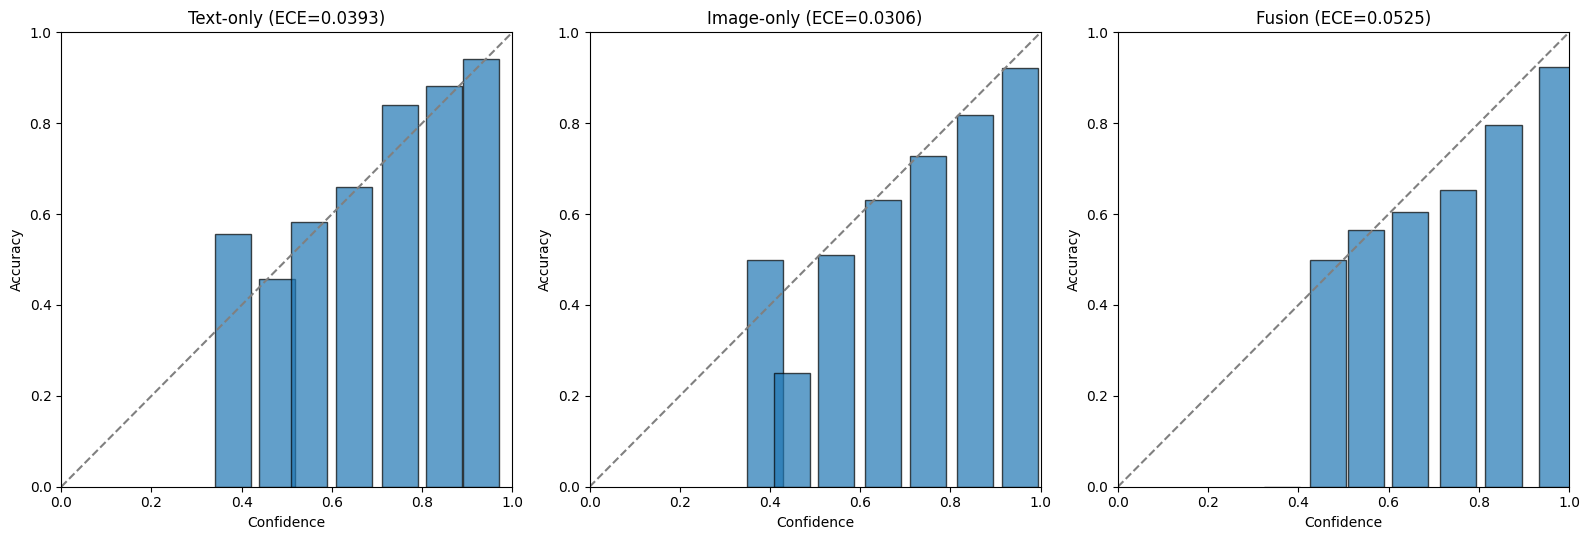

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
model_names = ['text_only', 'image_only', 'fusion']
titles = ['Text-only', 'Image-only', 'Fusion']

for ax, name, title in zip(axes, model_names, titles):
    bins = results[name]['calibration_bins']
    conf = [b['confidence'] for b in bins]
    acc_ = [b['accuracy'] for b in bins]
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
    ax.bar(conf, acc_, width=0.08, alpha=0.7, edgecolor='black')
    ax.set_title(f"{title} (ECE={results[name]['ece']:.4f})")
    ax.set_xlabel('Confidence')
    ax.set_ylabel('Accuracy')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fusion_stage_reliability_comparison.png', dpi=150)
plt.show()
